# Universidad Autonoma de Aguascalientes
# Departamento: Ciencias de la Computacion
# Carrera: Ingenieria en Computacion Inteligente
## Curso: Sistemas Expertos
## Maestro: Dr.Francisco Javier Lunas Rosas
## Alumno:
### Semestre: Agosto_Diciembre del 2026


## ¿Que es una convolución?

### Una convolución es simplemente una operación matematica que se realiza sobre los valores de los pixeles de una imagen.

### Se utilizan diferentes nucelos(kernels) o filtros para procesar una imagen hacia una estructrua conveniente para realizar cierta tarea o simplemente por estetica.

### Practica # 4. Operación matematica de Convolución en Imagenes

### En esta practica implementaremos diferentes nucleos(kernels) o filtros para modificar, analizar o extraer informacion de una imagen mediante la operación de convolución.

## Paso 1: Añadir las librerias necesarias.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pylab as plt
from PIL import Image, ImageFilter

## Paso 2: Especificamos la ruta y cargamos la imagen.

[[136 126 123 ... 180 187 170]
 [104 115 121 ... 176 181 183]
 [104 118 127 ... 175 178 193]
 ...
 [139 140 140 ... 118 115 139]
 [139 140 140 ... 124 122 142]
 [138 139 139 ... 120 105 131]]


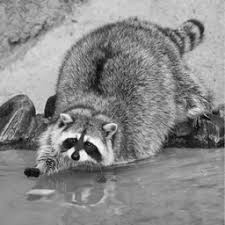

In [2]:
os.chdir("C:/Users/maluc/Downloads")
with Image.open("mapache.png", 'r') as im:
    pixel_array = np.array(im, dtype = "uint8")

print(pixel_array)
im

## Paso 3: Cargamos la Imagen desde un archivo ".csv". Cargamos el archivo en formato csv que contiene la representación de pixeles de la imagen mapache.jpeg

In [3]:
dt_mapache = pd.read_csv("mapache.csv",sep = ";",decimal=".",header = None, index_col = None)
dt_mapache

,0,1,2,3,4,5,6,7,8,9,...,215,216,217,218,219,220,221,222,223,224
0,136,126,123,129,129,121,121,127,111,124,...,186,193,196,195,188,179,176,180,187,170
1,104,115,121,123,129,134,126,111,124,124,...,186,197,199,197,188,178,174,176,181,183
2,104,118,127,126,126,131,129,121,139,128,...,186,199,199,195,187,178,174,175,178,193
3,130,134,145,151,141,126,127,138,144,136,...,186,195,193,189,184,180,178,179,181,193
4,142,143,154,167,164,146,133,131,141,146,...,186,186,183,181,180,182,185,187,187,192
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
220,139,140,140,141,142,143,143,144,144,144,...,129,128,129,129,128,126,121,117,114,143
221,139,140,140,141,142,143,143,144,144,144,...,134,132,132,131,129,124,119,113,110,138
222,139,140,140,141,142,143,143,144,144,144,...,135,131,131,132,130,127,122,118,115,139
223,139,140,140,141,142,143,143,144,144,144,...,130,128,129,131,131,130,127,124,122,142


## Paso 4: Convertir un Array a una Imagen

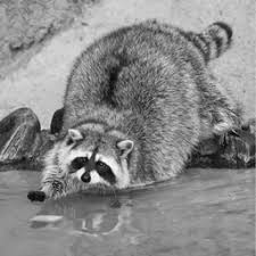

In [5]:
im = Image.fromarray(np.array(dt_mapache, dtype = "uint8"), mode = 'L')
im.resize((256,256))

## Paso 5: Aplicamos filtros o nucleos. Vamos a utilizar la funcion Kernel() del módulo ImageFilter y la funcion filter() del modulo Image.

## 5.1 Filtro de identidad. El filtro de identidad en imagenes es el más simple de todos: no cambia la imagen. Su función es devolver exactamente la misma imagen despues de aplicar la convolución. Solo toma el valor del pixel central e ignora los vecinos.

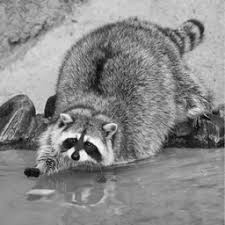

In [7]:
km = [0, 0, 0,
      0, 1, 0,
      0, 0, 0]
k = ImageFilter.Kernel(size=(3,3), kernel = km, scale= 1)

im2 = im.filter(k)
im2

## 5.2 Desenfoque. El filtro de desenfoque(blur) se usa para suavizar una imagen, reduciendo detalles finos y varaiciones bruscas entre pixeles. Toma cada pixel y lo reemplaza por un promedio de sus vecinos.

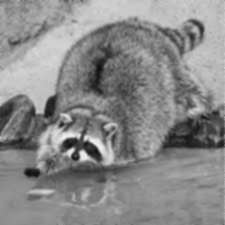

In [8]:
km = (
    1, 1, 1,
    1, 1, 1,
    1, 1, 1,
)
#Utilice diferente escala.
k = ImageFilter.Kernel(size=(3,3), kernel = km, scale= 9)

im2 = im.filter(k)
im2

## 5.3 Enfoque. El filtro de enfoque(sharpen) se usa para resaltar los detalles y hacer que una imagen se vea más nitida. Hace que las zonas donde hay cambios(bordes, texturas) se vean más marcadas.

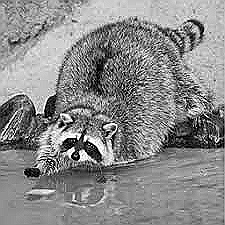

In [9]:
km = (
    0, -1, 0,
    -1, 5, -1,
    0, -1, 0
)
k = ImageFilter.Kernel(size=(3,3), kernel = km, scale= 1)
im2 = im.filter(k)
im2